In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ucitavanje podataka
df = pd.read_csv("cars.csv")

# Prikaz osnovnih informacija
print("Broj redova i kolona:", df.shape)
print("\nNazivi kolona:")
print(df.columns.tolist())

print("\nPrvih 5 redova:")
display(df.head())

Broj redova i kolona: (56244, 12)

Nazivi kolona:
['make', 'model', 'priceUSD', 'year', 'condition', 'mileage(kilometers)', 'fuel_type', 'volume(cm3)', 'color', 'transmission', 'drive_unit', 'segment']

Prvih 5 redova:


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B


Pocetni oblik podataka: (56244, 12)


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B



Nazivi kolona:
['make', 'model', 'priceUSD', 'year', 'condition', 'mileage(kilometers)', 'fuel_type', 'volume(cm3)', 'color', 'transmission', 'drive_unit', 'segment']

Tipovi podataka:
make                       str
model                      str
priceUSD                 int64
year                     int64
condition                  str
mileage(kilometers)    float64
fuel_type                  str
volume(cm3)            float64
color                      str
transmission               str
drive_unit                 str
segment                    str
dtype: object

Nedostajuce vrijednosti:


segment                5291
drive_unit             1905
volume(cm3)              47
make                      0
year                      0
priceUSD                  0
model                     0
condition                 0
fuel_type                 0
mileage(kilometers)       0
transmission              0
color                     0
dtype: int64


Broj dupliranih redova: 87

Statistika numerickih kolona:


,priceUSD,year,mileage(kilometers),volume(cm3)
count,56244.000000,56244.000000,5.624400e+04,56197.000000
mean,7415.456440,2003.454840,2.443956e+05,2104.860615
std,8316.959261,8.144247,3.210307e+05,959.201633
min,48.000000,1910.000000,0.000000e+00,500.000000
25%,2350.000000,1998.000000,1.370000e+05,1600.000000
50%,5350.000000,2004.000000,2.285000e+05,1996.000000
75%,9807.500000,2010.000000,3.100000e+05,2300.000000
max,235235.000000,2019.000000,9.999999e+06,20000.000000



Oblik podataka nakon ciscenja: (56157, 12)


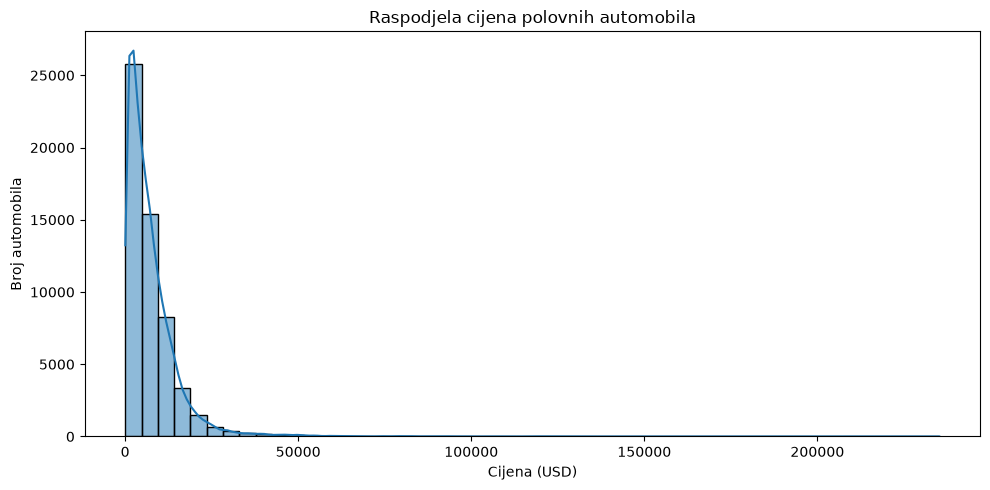


Broj numerickih karakteristika: 6
Broj kategorickih karakteristika: 8

Broj trening primjera: 44925
Broj test primjera: 11232

Treniranje modela: Linear Regression
MAE:  2206.07
MSE:  22303459.43
RMSE: 4722.65
R2:   0.6677

Treniranje modela: Decision Tree
MAE:  1530.47
MSE:  13640367.37
RMSE: 3693.29
R2:   0.7968

Treniranje modela: Random Forest
MAE:  1405.90
MSE:  12080118.13
RMSE: 3475.65
R2:   0.8200

POREDJENJE MODELA:


,Model,MAE,MSE,RMSE,R2
2,Random Forest,1405.904313,1.208012e+07,3475.646433,0.820016
1,Decision Tree,1530.465214,1.364037e+07,3693.286798,0.796769
0,Linear Regression,2206.074371,2.230346e+07,4722.653855,0.667696


Najbolji model prema MAE: Random Forest


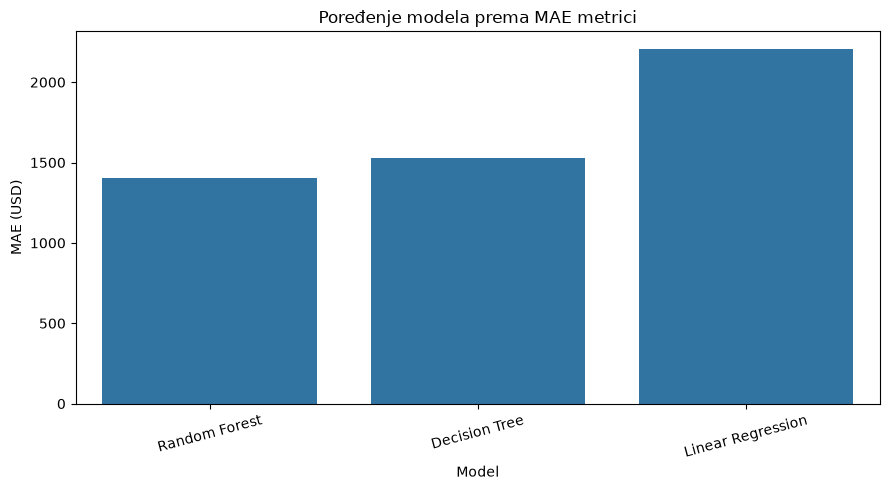


PRIMJERI PREDVIDJANJA:


,Stvarna cijena,Predvidjena cijena,Apsolutna greska
0,4300,3647.16,652.84
1,19950,22311.64,2361.64
2,12000,11557.93,442.07
3,9700,9073.49,626.51
4,8700,8023.88,676.12
5,550,1618.42,1068.42
6,14500,11657.26,2842.74
7,3000,2296.28,703.72
8,1000,2117.18,1117.18
9,16000,11619.81,4380.19



Model je sacuvan kao car_price_model.joblib
Velicina modela: 0.47 MB

ZAKLJUCAK
Testirana su tri regresiona modela.
Najbolji model prema MAE metrici: Random Forest
MAE najboljeg modela: 1405.90 USD
Model je sacuvan i moze se koristiti za nova predvidjanja.


In [2]:

# ============================================================
# PROJEKAT: PREDIKCIJA CIJENE POLOVNIH AUTOMOBILA
# Jupyter Notebook - analiza, treniranje i evaluacija modela
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# 1. UCITAVANJE PODATAKA

df = pd.read_csv("cars.csv")
df.columns = df.columns.str.strip()

print("Pocetni oblik podataka:", df.shape)
display(df.head())

# 2. OSNOVNA ANALIZA PODATAKA

print("\nNazivi kolona:")
print(df.columns.tolist())

print("\nTipovi podataka:")
print(df.dtypes)

print("\nNedostajuce vrijednosti:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nBroj dupliranih redova:", df.duplicated().sum())

print("\nStatistika numerickih kolona:")
display(df.describe())

# 3. CISCENJE PODATAKA

df = df.drop_duplicates()

df["priceUSD"] = pd.to_numeric(df["priceUSD"], errors="coerce")
df = df.dropna(subset=["priceUSD"])
df = df[df["priceUSD"] > 0]

for column in ["year", "mileage(kilometers)", "volume(cm3)"]:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

print("\nOblik podataka nakon ciscenja:", df.shape)

# 4. GRAFICKA ANALIZA CIJENA

plt.figure(figsize=(10, 5))
sns.histplot(df["priceUSD"], bins=50, kde=True)
plt.title("Raspodjela cijena polovnih automobila")
plt.xlabel("Cijena (USD)")
plt.ylabel("Broj automobila")
plt.tight_layout()
plt.show()

# 5. INZENJERING KARAKTERISTIKA

if "year" in df.columns:
    df["car_age"] = (2026 - df["year"]).clip(lower=0, upper=100)

if "mileage(kilometers)" in df.columns and "car_age" in df.columns:
    df["mileage_per_year"] = (
        df["mileage(kilometers)"] / df["car_age"].clip(lower=1)
    )

if "volume(cm3)" in df.columns:
    df["engine_volume_liters"] = df["volume(cm3)"] / 1000

# 6. PRIPREMA PODATAKA ZA MODEL

X = df.drop(columns=["priceUSD"])
y = df["priceUSD"]

# Izbacivanje kolona koje su potpuno prazne
X = X.dropna(axis=1, how="all")

numeric_columns = X.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = X.select_dtypes(exclude=["number"]).columns.tolist()

print("\nBroj numerickih karakteristika:", len(numeric_columns))
print("Broj kategorickih karakteristika:", len(categorical_columns))

# 7. PRETPROCESIRANJE PODATAKA

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# 8. PODJELA NA TRENING I TEST PODATKE

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nBroj trening primjera:", len(X_train))
print("Broj test primjera:", len(X_test))

# 9. DEFINISANJE TRI MODELA

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=10,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=20,
        max_depth=10,
        min_samples_leaf=10,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )
}

# 10. TRENIRANJE I EVALUACIJA

results = []
best_model = None
best_mae = float("inf")

for name, algorithm in models.items():
    print(f"\nTreniranje modela: {name}")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"MAE:  {mae:.2f}")
    print(f"MSE:  {mse:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2:   {r2:.4f}")

    if mae < best_mae:
        best_mae = mae
        best_model = pipeline

# 11. POREĐENJE MODELA

results_df = pd.DataFrame(results).sort_values("MAE")

print("\nPOREDJENJE MODELA:")
display(results_df)

print("Najbolji model prema MAE:", results_df.iloc[0]["Model"])

# 12. GRAFIKON POREĐENJA MAE

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Poređenje modela prema MAE metrici")
plt.ylabel("MAE (USD)")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 13. PRIMJERI PREDVIĐANJA

predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Stvarna cijena": y_test.to_numpy()[:10],
    "Predvidjena cijena": predictions[:10]
})

comparison["Apsolutna greska"] = abs(
    comparison["Stvarna cijena"] -
    comparison["Predvidjena cijena"]
)

print("\nPRIMJERI PREDVIDJANJA:")
display(comparison.round(2))

# 14. ČUVANJE NAJBOLJEG MODELA

joblib.dump(best_model, "car_price_model.joblib", compress=3)

size_mb = os.path.getsize("car_price_model.joblib") / (1024 * 1024)

print("\nModel je sacuvan kao car_price_model.joblib")
print(f"Velicina modela: {size_mb:.2f} MB")

# 15. ZAKLJUČAK

print("\nZAKLJUCAK")
print("Testirana su tri regresiona modela.")
print("Najbolji model prema MAE metrici:",
      results_df.iloc[0]["Model"])
print(f"MAE najboljeg modela: {results_df.iloc[0]['MAE']:.2f} USD")
print("Model je sacuvan i moze se koristiti za nova predvidjanja.")
